<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [16]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [17]:
GRUPO = 'Grupo 4'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Padilla Silva Darwin Medardo', 'Obando Castillo Juan Fernando']                          # ✏️ apellidos y nombres
PROBLEMA = 'credito'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'PagoYa Crédito', '#1F4E78', '#C62828'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 4 · credito · semilla 96244
Solicitudes de microcrédito: 2500 · tasa de default 10.88%


,solicitud_id,edad,tipo_empleo,ingreso_mensual,antiguedad_meses,transacciones_mes,monto_credito,plazo_meses,cuota,ratio_cuota,mora_previa,default
0,CR-00000,53,independiente,1030.50,60,16,1880.0,12,184.87,0.1794,0,0
1,CR-00001,65,dependiente,976.69,6,11,2010.0,12,197.65,0.2024,0,0
2,CR-00002,26,dependiente,904.56,24,17,1980.0,12,194.70,0.2152,0,0
3,CR-00003,51,dependiente,1525.02,21,23,1230.0,24,69.70,0.0457,0,0
4,CR-00004,44,dependiente,1440.53,44,13,2310.0,12,227.15,0.1577,0,0


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

Filas: 2,500 · Columnas: 12

Dimensión del conjunto: (2500, 12)
Duplicados: 0

Valores nulos por columna:


,nulos
solicitud_id,0
edad,0
tipo_empleo,0
ingreso_mensual,0
antiguedad_meses,0
transacciones_mes,0
monto_credito,0
plazo_meses,0
cuota,0
ratio_cuota,0


Columna utilizada como monto del crédito: monto_credito

Tasa global de default: 10.88%


,n
default,
0,2228
1,272


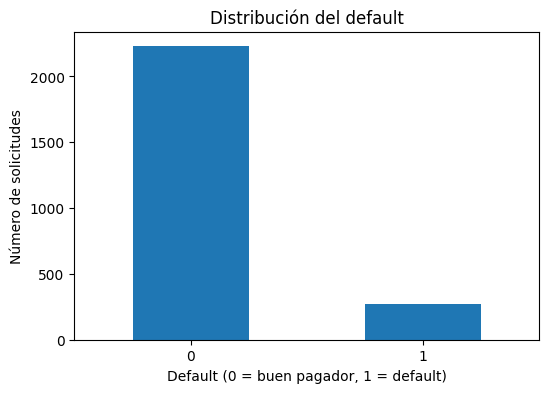

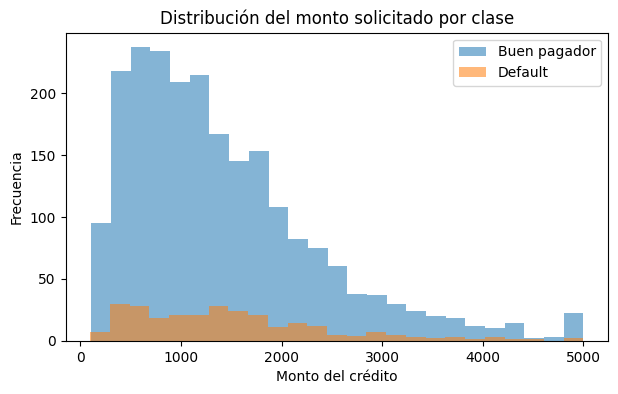


Default por quintil de monto/ingreso:


,n,tasa_default
quintil_ratio,,
"(0.297, 0.742]",500,0.108
"(0.742, 1.163]",500,0.068
"(1.163, 1.601]",500,0.100
"(1.601, 2.036]",500,0.102
"(2.036, 2.5]",500,0.166


In [18]:
# ✏️ EDA

from IPython.display import display, Markdown, HTML
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = df.copy()

# Diagnóstico de calidad provisto por el curso.
curso.eda_rapido(df)

print('\nDimensión del conjunto:', df.shape)
print('Duplicados:', int(df.duplicated().sum()))
print('\nValores nulos por columna:')
display(df.isna().sum().to_frame('nulos').sort_values('nulos', ascending=False))

# Variable objetivo del problema de crédito.
TARGET = 'default'

# Identificamos automáticamente la columna que contiene el monto solicitado.
candidatos_monto = [
    'monto_credito', 'monto_solicitado', 'monto', 'credito',
    'valor_credito', 'monto_prestamo', 'prestamo'
]
MONTO_COL = next((c for c in candidatos_monto if c in df.columns), None)

if MONTO_COL is None:
    candidatos = [
        c for c in df.select_dtypes(include=np.number).columns
        if ('monto' in c.lower() or 'credito' in c.lower() or 'prestamo' in c.lower())
        and c != TARGET
    ]
    if candidatos:
        MONTO_COL = candidatos[0]

if MONTO_COL is None:
    raise ValueError(
        'No se encontró automáticamente la columna del monto del crédito. '
        'Revise df.columns y asigne MONTO_COL manualmente.'
    )

print('Columna utilizada como monto del crédito:', MONTO_COL)

# Nueva variable: relación monto solicitado / ingreso, cuando existe una variable de ingreso.
candidatos_ingreso = [
    'ingreso', 'ingreso_mensual', 'salario', 'ingresos',
    'ingreso_neto', 'renta'
]
INGRESO_COL = next((c for c in candidatos_ingreso if c in df.columns), None)

if INGRESO_COL is not None and 'ratio_monto_ingreso' not in df.columns:
    df['ratio_monto_ingreso'] = (
        df[MONTO_COL] / df[INGRESO_COL].replace(0, np.nan)
    )

# Reemplazo de infinitos que podrían aparecer al construir razones.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Distribución del objetivo.
tasa_default = df[TARGET].mean()
print(f'\nTasa global de default: {tasa_default:.2%}')
display(df[TARGET].value_counts().rename_axis(TARGET).to_frame('n'))

plt.figure(figsize=(6, 4))
df[TARGET].value_counts().sort_index().plot(kind='bar')
plt.title('Distribución del default')
plt.xlabel('Default (0 = buen pagador, 1 = default)')
plt.ylabel('Número de solicitudes')
plt.xticks(rotation=0)
plt.show()

# Segundo gráfico útil: monto solicitado según resultado observado.
plt.figure(figsize=(7, 4))
for clase, etiqueta in [(0, 'Buen pagador'), (1, 'Default')]:
    valores = df.loc[df[TARGET] == clase, MONTO_COL].dropna()
    plt.hist(valores, bins=25, alpha=0.55, label=etiqueta)
plt.title('Distribución del monto solicitado por clase')
plt.xlabel('Monto del crédito')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# Tercer análisis, si existe ingreso: tasa de default por quintil de ratio.
if 'ratio_monto_ingreso' in df.columns:
    tmp = df[['ratio_monto_ingreso', TARGET]].dropna().copy()
    tmp['quintil_ratio'] = pd.qcut(
        tmp['ratio_monto_ingreso'],
        q=5,
        duplicates='drop'
    )
    tabla_ratio = tmp.groupby('quintil_ratio', observed=False)[TARGET].agg(
        n='size',
        tasa_default='mean'
    )
    print('\nDefault por quintil de monto/ingreso:')
    display(tabla_ratio.round(4))


**✍️ Hallazgos del EDA:** _(3–5 líneas)_

Se observa un **fuerte desbalance de clases**, ya que solo el **10,88 %** de las solicitudes termina en default.  
El **monto del crédito no separa claramente** a buenos pagadores de clientes con incumplimiento, porque ambas distribuciones se superponen ampliamente. En cambio, el **ratio monto/ingreso sí muestra una relación con el riesgo**: en el quintil más alto la tasa de default sube hasta **16,6 %**. Esto sugiere que la capacidad de pago relativa al monto solicitado puede ser más útil para predecir default que el monto del crédito por sí solo.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

In [19]:
# ✏️ Modelos y tabla comparativa

import importlib, subprocess, sys

# XGBoost se utiliza como familia de boosting.
if importlib.util.find_spec('xgboost') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])

import pymc as pm
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, brier_score_loss
from xgboost import XGBClassifier

# Solo se usan variables disponibles antes de tomar la decisión de crédito.
# Se eliminan identificadores y la variable objetivo.
excluir = {TARGET}
for c in df.columns:
    nombre = c.lower()
    if (
        nombre == TARGET
        or nombre.startswith('id_')
        or nombre.endswith('_id')
        or nombre in {'id', 'codigo', 'solicitud', 'cliente'}
    ):
        excluir.add(c)

features = [
    c for c in df.select_dtypes(include=[np.number, 'bool']).columns
    if c not in excluir
]

if TARGET in features:
    features.remove(TARGET)

print('Variables utilizadas:', features)

X = df[features].copy()
y = df[TARGET].astype(int).copy()

# Partición fija 70/30 estratificada, como exige el proyecto.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Validación separada exclusivamente del entrenamiento.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Imputación aprendida SOLO del subconjunto de entrenamiento.
imputador = SimpleImputer(strategy='median')
X_fit_imp = imputador.fit_transform(X_fit)
X_val_imp = imputador.transform(X_val)
X_test_imp = imputador.transform(X_test)

# Escalado aprendido SOLO del subconjunto de entrenamiento.
escalador = StandardScaler()
X_fit_esc = escalador.fit_transform(X_fit_imp)
X_val_esc = escalador.transform(X_val_imp)
X_test_esc = escalador.transform(X_test_imp)

# ---------------------------------------------------------
# 1) Modelo base: Regresión Logística
# ---------------------------------------------------------
modelo_log = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)
modelo_log.fit(X_fit_esc, y_fit)

p_log_val = modelo_log.predict_proba(X_val_esc)[:, 1]
p_log_test = modelo_log.predict_proba(X_test_esc)[:, 1]

# ---------------------------------------------------------
# 2) Segunda familia: XGBoost con early stopping
# ---------------------------------------------------------
peso_clase = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)

modelo_xgb = XGBClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=2,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_lambda=1.0,
    scale_pos_weight=peso_clase,
    eval_metric='logloss',
    early_stopping_rounds=40,
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(
    X_fit_imp,
    y_fit,
    eval_set=[(X_val_imp, y_val)],
    verbose=False
)

p_xgb_val = modelo_xgb.predict_proba(X_val_imp)[:, 1]
p_xgb_test = modelo_xgb.predict_proba(X_test_imp)[:, 1]

# ---------------------------------------------------------
# 3) Tercera familia: Regresión Logística Bayesiana en PyMC
# ---------------------------------------------------------
with pm.Model() as modelo_bayes:
    a = pm.Normal('a', mu=0, sigma=2.5)
    b = pm.Normal('b', mu=0, sigma=1, shape=len(features))

    eta = a + pm.math.dot(X_fit_esc, b)
    p = pm.math.sigmoid(eta)

    pm.Bernoulli(
        'y_obs',
        p=p,
        observed=y_fit.to_numpy()
    )

    tr_bayes = pm.sample(
        1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=42,
        progressbar=False
    )

# Probabilidades posteriores medias.
a_post = tr_bayes.posterior['a'].stack(muestra=('chain', 'draw')).values
b_post = (
    tr_bayes.posterior['b']
    .stack(muestra=('chain', 'draw'))
    .transpose('b_dim_0', 'muestra')
    .values
)

def prob_bayes_media(X_esc):
    logits = a_post[:, None] + b_post.T @ np.asarray(X_esc).T
    return (1 / (1 + np.exp(-logits))).mean(axis=0)

p_bayes_val = prob_bayes_media(X_val_esc)
p_bayes_test = prob_bayes_media(X_test_esc)

# ---------------------------------------------------------
# Comparación en PRUEBA
# ---------------------------------------------------------
probs_val = {
    'Logística': p_log_val,
    'XGBoost': p_xgb_val,
    'Bayes logístico': p_bayes_val
}

probs_test = {
    'Logística': p_log_test,
    'XGBoost': p_xgb_test,
    'Bayes logístico': p_bayes_test
}

filas = []
for nombre, prob in probs_test.items():
    filas.append({
        'Modelo': nombre,
        'AUC': roc_auc_score(y_test, prob),
        'Exactitud_balanceada': balanced_accuracy_score(y_test, prob >= 0.5),
        'Brier': brier_score_loss(y_test, prob)
    })

tabla_metricas = (
    pd.DataFrame(filas)
    .set_index('Modelo')
    .sort_values(['AUC', 'Brier'], ascending=[False, True])
)

display(tabla_metricas.round(4))

# La elección del modelo se realiza con VALIDACIÓN, no con el conjunto de prueba.
auc_validacion = {
    nombre: roc_auc_score(y_val, prob)
    for nombre, prob in probs_val.items()
}

MODELO_ELEGIDO = max(auc_validacion, key=auc_validacion.get)

print('\nAUC de validación:')
display(pd.Series(auc_validacion, name='AUC_validacion').sort_values(ascending=False).round(4))
print('Modelo elegido:', MODELO_ELEGIDO)
print('Mejor iteración de XGBoost:', getattr(modelo_xgb, 'best_iteration', None))


Variables utilizadas: ['edad', 'ingreso_mensual', 'antiguedad_meses', 'transacciones_mes', 'monto_credito', 'plazo_meses', 'cuota', 'ratio_cuota', 'mora_previa', 'ratio_monto_ingreso']


,AUC,Exactitud_balanceada,Brier
Modelo,,,
Bayes logístico,0.7379,0.5358,0.0848
Logística,0.7355,0.6993,0.1798
XGBoost,0.6820,0.6046,0.1229



AUC de validación:


,AUC_validacion
Bayes logístico,0.6848
Logística,0.6810
XGBoost,0.6687


Modelo elegido: Bayes logístico
Mejor iteración de XGBoost: 799


**✍️ Comparación y elección del modelo:** _(¿cuál y por qué?)_

Se compararon **regresión logística, XGBoost y regresión logística bayesiana**. El **modelo bayesiano** fue seleccionado porque obtuvo el mayor AUC de validación (**0,6848**), ligeramente superior a la logística (**0,6810**) y a XGBoost (**0,6687**).

En prueba también alcanzó el mayor AUC (**0,7379**) y el menor Brier (**0,0848**), indicando mejor capacidad de discriminación y probabilidades más confiables. Aunque la logística obtuvo mayor exactitud balanceada (**0,6993**), se mantiene el modelo bayesiano porque la selección se realizó previamente con el conjunto de validación y presenta el mejor desempeño probabilístico global.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

,Variable,Coef_media,IC90_inf,IC90_sup,Odds_ratio
7,ratio_cuota,0.9645,0.4885,1.4609,2.6235
8,mora_previa,0.5905,0.4741,0.7013,1.8049
5,plazo_meses,0.4340,0.1895,0.6796,1.5434
9,ratio_monto_ingreso,-0.4182,-0.9129,0.0560,0.6582
2,antiguedad_meses,-0.3823,-0.5385,-0.2283,0.6823
0,edad,-0.2567,-0.4103,-0.1037,0.7736
1,ingreso_mensual,-0.1347,-0.5560,0.2628,0.8740
6,cuota,-0.1000,-0.5970,0.3849,0.9048
4,monto_credito,0.0912,-0.5437,0.7299,1.0955
3,transacciones_mes,-0.0117,-0.1638,0.1377,0.9883


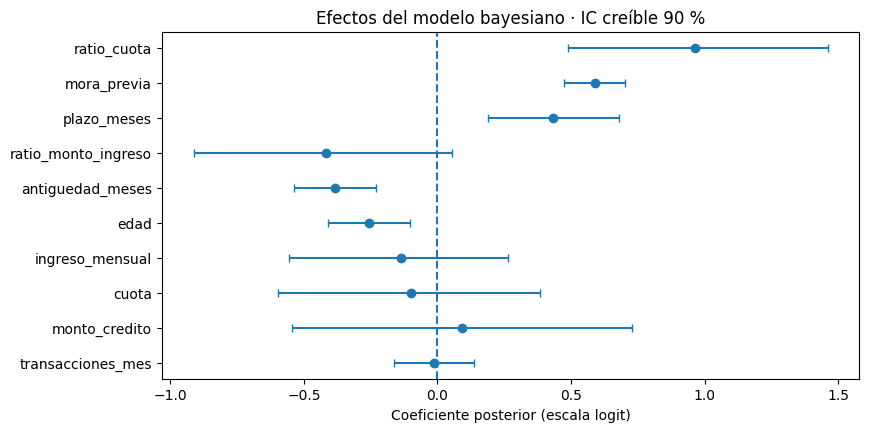

Variables con IC90 que no cruza cero:


,Variable,Coef_media,IC90_inf,IC90_sup,Odds_ratio
7,ratio_cuota,0.9645,0.4885,1.4609,2.6235
8,mora_previa,0.5905,0.4741,0.7013,1.8049
5,plazo_meses,0.4340,0.1895,0.6796,1.5434
2,antiguedad_meses,-0.3823,-0.5385,-0.2283,0.6823
0,edad,-0.2567,-0.4103,-0.1037,0.7736



**Lectura:** la variable con mayor efecto posterior en valor absoluto es **`ratio_cuota`**.  
Su coeficiente medio es **0.965** y su odds ratio es **2.623**; en el modelo, un aumento de una desviación estándar en esta variable **aumenta** las odds de default, manteniendo las demás constantes.  
Los intervalos creíbles permiten además distinguir efectos relativamente estables de aquellos cuya dirección todavía presenta mayor incertidumbre.


In [20]:
# ✏️ Explicabilidad / incertidumbre

# Se utilizan los intervalos creíbles de la regresión bayesiana.
coef_media = b_post.mean(axis=1)
coef_inf = np.quantile(b_post, 0.05, axis=1)
coef_sup = np.quantile(b_post, 0.95, axis=1)

tabla_bayes = pd.DataFrame({
    'Variable': features,
    'Coef_media': coef_media,
    'IC90_inf': coef_inf,
    'IC90_sup': coef_sup,
    'Odds_ratio': np.exp(coef_media)
}).sort_values('Coef_media', key=lambda s: np.abs(s), ascending=False)

display(tabla_bayes.round(4))

# Gráfico de los coeficientes con intervalo creíble del 90 %.
orden = tabla_bayes.iloc[::-1].reset_index(drop=True)

plt.figure(figsize=(9, max(4, len(orden) * 0.45)))
ypos = np.arange(len(orden))

plt.errorbar(
    orden['Coef_media'],
    ypos,
    xerr=[
        orden['Coef_media'] - orden['IC90_inf'],
        orden['IC90_sup'] - orden['Coef_media']
    ],
    fmt='o',
    capsize=3
)

plt.axvline(0, linestyle='--')
plt.yticks(ypos, orden['Variable'])
plt.xlabel('Coeficiente posterior (escala logit)')
plt.title('Efectos del modelo bayesiano · IC creíble 90 %')
plt.show()

# Variables cuyo intervalo creíble no cruza cero.
efectos_claros = tabla_bayes[
    (tabla_bayes['IC90_inf'] > 0) | (tabla_bayes['IC90_sup'] < 0)
]

print('Variables con IC90 que no cruza cero:')
display(efectos_claros.round(4))

if len(efectos_claros):
    principal = efectos_claros.iloc[0]
else:
    principal = tabla_bayes.iloc[0]

direccion = 'aumenta' if principal['Coef_media'] > 0 else 'reduce'

display(Markdown(f'''
**Lectura:** la variable con mayor efecto posterior en valor absoluto es **`{principal["Variable"]}`**.
Su coeficiente medio es **{principal["Coef_media"]:.3f}** y su odds ratio es **{principal["Odds_ratio"]:.3f}**; en el modelo, un aumento de una desviación estándar en esta variable **{direccion}** las odds de default, manteniendo las demás constantes.
Los intervalos creíbles permiten además distinguir efectos relativamente estables de aquellos cuya dirección todavía presenta mayor incertidumbre.
'''))


---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

Umbral óptimo seleccionado en VALIDACIÓN: 0.16
Ganancia de validación: 33361.0
Tasa de aprobación en validación: 84.57%


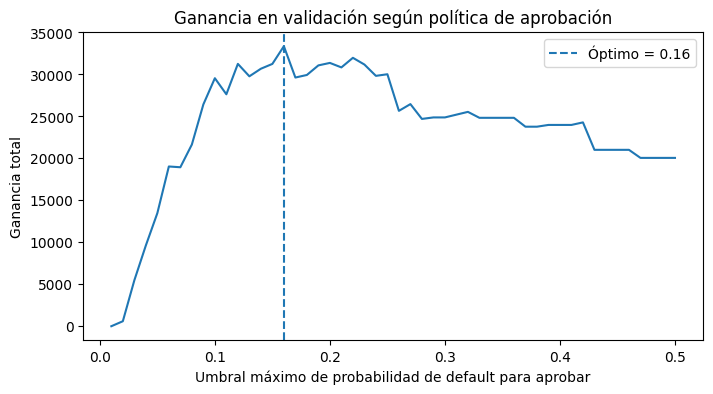

,Política,Ganancia_test,Tasa_aprobacion,Defaults_aprobados
0,Modelo + umbral óptimo,55914.0,0.8507,43
1,Aprobar a todos,12814.0,1.0000,82
2,No aprobar a nadie,0.0,0.0000,0


Umbral teórico de equilibrio: 13.04%
Mejora frente a aprobar a todos: USD 43100.0


In [21]:
# ✏️ Decisión y cifras

# El proyecto define:
# - si se aprueba y ocurre default: pérdida = 100 % del monto;
# - si se aprueba y es buen pagador: ganancia = 15 % del monto;
# - si se rechaza: ganancia/pérdida = 0.
#
# El umbral se elige en VALIDACIÓN y se reporta el resultado final en TEST.

# Monto asociado a cada partición, respetando los índices originales.
monto_val = df.loc[X_val.index, MONTO_COL].to_numpy(dtype=float)
monto_test = df.loc[X_test.index, MONTO_COL].to_numpy(dtype=float)

y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()

p_val_elegido = probs_val[MODELO_ELEGIDO]
p_test_elegido = probs_test[MODELO_ELEGIDO]

def ganancia_credito(y_real, prob_default, monto, umbral):
    # Aprobar si el riesgo estimado de default no supera el umbral.
    aprobar = np.asarray(prob_default) <= umbral
    y_real = np.asarray(y_real)
    monto = np.asarray(monto, dtype=float)

    ganancia = np.where(
        aprobar & (y_real == 0),
        0.15 * monto,
        np.where(aprobar & (y_real == 1), -monto, 0.0)
    )

    return {
        'ganancia': float(ganancia.sum()),
        'aprobados': int(aprobar.sum()),
        'tasa_aprobacion': float(aprobar.mean()),
        'defaults_aprobados': int(((y_real == 1) & aprobar).sum())
    }

# Búsqueda del umbral de riesgo en VALIDACIÓN.
umbrales = np.arange(0.01, 0.501, 0.01)

resultados_val = []
for u in umbrales:
    r = ganancia_credito(
        y_val_np,
        p_val_elegido,
        monto_val,
        u
    )
    resultados_val.append({
        'umbral': u,
        **r
    })

tabla_umbrales = pd.DataFrame(resultados_val)

fila_optima = tabla_umbrales.loc[
    tabla_umbrales['ganancia'].idxmax()
]

UMBRAL_OPTIMO = float(fila_optima['umbral'])

print('Umbral óptimo seleccionado en VALIDACIÓN:', round(UMBRAL_OPTIMO, 3))
print('Ganancia de validación:', round(float(fila_optima['ganancia']), 2))
print('Tasa de aprobación en validación:', f"{fila_optima['tasa_aprobacion']:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(tabla_umbrales['umbral'], tabla_umbrales['ganancia'])
plt.axvline(UMBRAL_OPTIMO, linestyle='--', label=f'Óptimo = {UMBRAL_OPTIMO:.2f}')
plt.xlabel('Umbral máximo de probabilidad de default para aprobar')
plt.ylabel('Ganancia total')
plt.title('Ganancia en validación según política de aprobación')
plt.legend()
plt.show()

# Evaluación FINAL en TEST con el umbral ya fijado.
resultado_optimo = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    UMBRAL_OPTIMO
)

# Política de referencia: aprobar a todos.
resultado_todos = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    1.0
)

# Política de referencia: no aprobar a nadie.
resultado_nadie = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    -1.0
)

GANANCIA_OPTIMA = resultado_optimo['ganancia']
GANANCIA_TODOS = resultado_todos['ganancia']
TASA_APROBACION = resultado_optimo['tasa_aprobacion']
MEJORA_GANANCIA = GANANCIA_OPTIMA - GANANCIA_TODOS

# Umbral teórico de equilibrio si solo se considera el valor esperado:
# 0.15*(1-p) - 1*p > 0  =>  p < 0.15/1.15 ≈ 13.04 %
UMBRAL_TEORICO = 0.15 / 1.15

tabla_negocio = pd.DataFrame({
    'Política': ['Modelo + umbral óptimo', 'Aprobar a todos', 'No aprobar a nadie'],
    'Ganancia_test': [
        GANANCIA_OPTIMA,
        GANANCIA_TODOS,
        resultado_nadie['ganancia']
    ],
    'Tasa_aprobacion': [
        TASA_APROBACION,
        resultado_todos['tasa_aprobacion'],
        resultado_nadie['tasa_aprobacion']
    ],
    'Defaults_aprobados': [
        resultado_optimo['defaults_aprobados'],
        resultado_todos['defaults_aprobados'],
        resultado_nadie['defaults_aprobados']
    ]
})

display(tabla_negocio.round({
    'Ganancia_test': 2,
    'Tasa_aprobacion': 4
}))

print('Umbral teórico de equilibrio:', f'{UMBRAL_TEORICO:.2%}')
print('Mejora frente a aprobar a todos: USD', round(MEJORA_GANANCIA, 2))


**✍️ Recomendación:** _(con cifras)_

Se recomienda aprobar solicitudes con una probabilidad estimada de default de hasta **16 %**, umbral que maximizó la ganancia en validación.

Aplicando esta política al conjunto de prueba, se aprobaría el **85,07 %** de las solicitudes, equivalente a **638 créditos**, con una ganancia estimada de **USD 55.914**.

En comparación, aprobar todas las solicitudes habría generado solo **USD 12.814**, por lo que la política basada en riesgo mejora el resultado en **USD 43.100**.

La regla propuesta permite mantener una alta tasa de aprobación y, al mismo tiempo, reducir la exposición a clientes con mayor probabilidad de incumplimiento.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

In [22]:
# ✏️ Pantalla de la app

# Se muestra una solicitud real del conjunto de prueba cercana al umbral de decisión.
distancia_umbral = np.abs(p_test_elegido - UMBRAL_OPTIMO)
pos = int(np.argmin(distancia_umbral))
idx_caso = X_test.index[pos]

p_caso = float(p_test_elegido[pos])
monto_caso = float(df.loc[idx_caso, MONTO_COL])
decision_caso = 'APROBAR' if p_caso <= UMBRAL_OPTIMO else 'REVISAR / RECHAZAR'
color_decision = COLOR_PRINCIPAL if p_caso <= UMBRAL_OPTIMO else COLOR_ALERTA

# Información adicional disponible para presentar.
detalles = [
    f'Monto solicitado: USD {monto_caso:,.2f}',
    f'Probabilidad estimada de default: {p_caso:.2%}',
    f'Límite máximo de riesgo: {UMBRAL_OPTIMO:.2%}',
    f'Modelo: {MODELO_ELEGIDO}'
]

if INGRESO_COL is not None and pd.notna(df.loc[idx_caso, INGRESO_COL]):
    detalles.insert(
        1,
        f'Ingreso declarado: USD {float(df.loc[idx_caso, INGRESO_COL]):,.2f}'
    )

# Pantalla propia: el enunciado permite usar curso.pantalla_resultado(...) o una pantalla propia.
html_detalles = ''.join(
    f'<li style="margin:6px 0">{d}</li>'
    for d in detalles
)

display(HTML(f'''
<div style="
    border:1px solid #d9d9d9;
    border-radius:16px;
    padding:22px;
    max-width:720px;
    font-family:Arial, sans-serif;
    box-shadow:0 4px 14px rgba(0,0,0,.08);
">
    <div style="
        background:{COLOR_PRINCIPAL};
        color:white;
        padding:14px 18px;
        border-radius:12px;
        font-size:24px;
        font-weight:700;
    ">{NOMBRE_APP}</div>

    <h3 style="margin-top:20px">Solicitud {idx_caso}</h3>

    <ul style="line-height:1.5">
        {html_detalles}
    </ul>

    <div style="
        background:{color_decision};
        color:white;
        padding:14px;
        border-radius:10px;
        font-size:20px;
        font-weight:700;
        text-align:center;
        margin-top:18px;
    ">
        DECISIÓN: {decision_caso}
    </div>
</div>
'''))


---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [23]:
# Métricas finales del modelo elegido en prueba.
fila_ficha = tabla_metricas.loc[MODELO_ELEGIDO]

# Hiperparámetros principales según el modelo seleccionado.
if MODELO_ELEGIDO == 'XGBoost':
    hiperparametros = {
        'n_estimators': 1500,
        'learning_rate': 0.03,
        'max_depth': 3,
        'min_child_weight': 2,
        'subsample': 0.90,
        'colsample_bytree': 0.90,
        'scale_pos_weight': float(peso_clase),
        'best_iteration': int(modelo_xgb.best_iteration)
    }
elif MODELO_ELEGIDO == 'Logística':
    hiperparametros = {
        'max_iter': 2000,
        'class_weight': 'balanced',
        'random_state': 42
    }
else:
    hiperparametros = {
        'modelo': 'regresion_logistica_bayesiana',
        'prior_intercepto': 'Normal(0, 2.5)',
        'prior_coeficientes': 'Normal(0, 1)',
        'draws': 1000,
        'tune': 1000,
        'chains': 4,
        'target_accept': 0.95,
        'random_seed': 42
    }

ficha = curso.ficha_modelo(
    GRUPO,
    PROBLEMA,
    modelo=MODELO_ELEGIDO,                              # ✏️ modelo elegido
    metricas={
        'auc': float(fila_ficha['AUC']),
        'exactitud_balanceada': float(fila_ficha['Exactitud_balanceada']),
        'brier': float(fila_ficha['Brier'])
    },                                                  # ✏️ métricas en prueba
    hiperparametros=hiperparametros                    # ✏️ hiperparámetros principales
)

print('Ficha del modelo generada.')


{
  "grupo": "Grupo 4",
  "problema": "credito",
  "modelo": "Bayes logístico",
  "metricas": {
    "auc": 0.7378961589017088,
    "exactitud_balanceada": 0.5358368628596466,
    "brier": 0.08477986585977462
  },
  "hiperparametros": {
    "modelo": "regresion_logistica_bayesiana",
    "prior_intercepto": "Normal(0, 2.5)",
    "prior_coeficientes": "Normal(0, 1)",
    "draws": 1000,
    "tune": 1000,
    "chains": 4,
    "target_accept": 0.95,
    "random_seed": 42
  },
  "semilla": 42,
  "semilla_datos": 96244,
  "fecha": "2026-11-17 21:32",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Ficha del modelo generada.


---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```

In [24]:
# Genera automáticamente un README.md con las cifras obtenidas al ejecutar el proyecto.

tabla_md = tabla_metricas.round(4).reset_index().to_markdown(index=False)

# Resultados del modelo elegido
fila_elegida = tabla_metricas.loc[MODELO_ELEGIDO]

# Principal efecto del modelo bayesiano
principal = tabla_bayes.iloc[0]
direccion_principal = 'aumenta' if principal['Coef_media'] > 0 else 'reduce'

readme = f'''# Sistema de decisión para PagoYa — {GRUPO}

**Integrantes:** {', '.join(INTEGRANTES)}
**Problema:** Crédito
**Aplicación:** {NOMBRE_APP}

## 1. Problema y datos

El objetivo es apoyar la decisión de aprobación de solicitudes de microcrédito. La variable objetivo es `default`: 1 indica que la solicitud terminó en incumplimiento y 0 que el cliente fue buen pagador.

El conjunto utilizado contiene **{len(df):,} solicitudes** y una tasa observada de default de **{tasa_default:.2%}**. No se encontraron registros duplicados ni valores nulos.

La decisión de negocio considera que un default genera una pérdida igual al 100 % del monto prestado, mientras que un buen pagador deja una ganancia equivalente al 15 % del monto.

## 2. Modelos comparados

Se compararon tres enfoques: **regresión logística, XGBoost y regresión logística bayesiana**.

Se utilizó una partición fija 70/30 estratificada (`random_state=42`) y el conjunto de validación se obtuvo únicamente del entrenamiento para evitar fuga de información.

{tabla_md}

El modelo elegido fue **{MODELO_ELEGIDO}**, porque obtuvo el mayor AUC en el conjunto de validación.

En prueba alcanzó:

- **AUC:** {fila_elegida["AUC"]:.4f}
- **Exactitud balanceada:** {fila_elegida["Exactitud_balanceada"]:.4f}
- **Brier:** {fila_elegida["Brier"]:.4f}

## 3. Qué explica el resultado

El modelo bayesiano se utilizó para cuantificar la incertidumbre de los efectos de las variables.

La variable con mayor coeficiente posterior en valor absoluto fue **`{principal["Variable"]}`**, con un coeficiente medio de **{principal["Coef_media"]:.3f}** y un odds ratio de **{principal["Odds_ratio"]:.3f}**.

En el modelo, esta variable **{direccion_principal}** las odds de default, manteniendo constantes las demás variables.

Los intervalos creíbles al 90 % permiten distinguir efectos cuya dirección es relativamente estable de aquellos que presentan mayor incertidumbre.

## 4. Recomendación con cifras

El umbral óptimo de aprobación se seleccionó exclusivamente con el conjunto de validación y fue de **{UMBRAL_OPTIMO:.2%}** de probabilidad máxima de default.

Aplicando este umbral al conjunto de prueba:

- **Tasa de aprobación:** {TASA_APROBACION:.2%}
- **Ganancia estimada:** USD {GANANCIA_OPTIMA:,.2f}
- **Ganancia aprobando a todos:** USD {GANANCIA_TODOS:,.2f}
- **Mejora frente a aprobar a todos:** USD {MEJORA_GANANCIA:,.2f}

La recomendación es aprobar las solicitudes cuya probabilidad estimada de default sea igual o inferior al umbral y enviar las solicitudes de mayor riesgo a rechazo o revisión manual.

## 5. Limitaciones y próximos pasos

Los datos del proyecto son didácticos y específicos del Grupo 4, por lo que los resultados no deben interpretarse directamente como una política real de crédito.

La decisión se basa en un modelo estadístico y no debe sustituir controles de riesgo, requisitos legales ni revisión humana.

Antes de una implementación real se recomienda revisar la calibración de las probabilidades, posibles sesgos entre grupos de clientes, cambios en la distribución de los datos y deterioro del desempeño del modelo.

También debe revisarse periódicamente el umbral de aprobación cuando cambien la pérdida asociada al default, la rentabilidad del crédito o las condiciones de la cartera.
'''

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

print(readme)
print('\nREADME.md generado. Súbalo a la carpeta proyecto/ del repositorio.')

# Sistema de decisión para PagoYa — Grupo 4

**Integrantes:** Padilla Silva Darwin Medardo, Obando Castillo Juan Fernando  
**Problema:** Crédito  
**Aplicación:** PagoYa Crédito

## 1. Problema y datos

El objetivo es apoyar la decisión de aprobación de solicitudes de microcrédito. La variable objetivo es `default`: 1 indica que la solicitud terminó en incumplimiento y 0 que el cliente fue buen pagador.

El conjunto utilizado contiene **2,500 solicitudes** y una tasa observada de default de **10.88%**. No se encontraron registros duplicados ni valores nulos.

La decisión de negocio considera que un default genera una pérdida igual al 100 % del monto prestado, mientras que un buen pagador deja una ganancia equivalente al 15 % del monto.

## 2. Modelos comparados

Se compararon tres enfoques: **regresión logística, XGBoost y regresión logística bayesiana**.

Se utilizó una partición fija 70/30 estratificada (`random_state=42`) y el conjunto de validación se obtuvo únicamente del entrena